# Diniz Ch.6 — Set-membership BNLMS QAM equalization

## 1. Setup

In [1]:
from pathlib import Path
import sys
from functools import partial

import numpy as np

project_root = next(path for path in [Path.cwd(), *Path.cwd().parents] if (path / "adsp").is_dir())
if str(project_root) not in sys.path:
  sys.path.insert(0, str(project_root))

from adsp import data, training, statistics as stats
from adsp import plotting as plot
from adsp import filters as af
from adsp import equalization as ae
from adsp.datasets import SampleBatch

plot.use_dark()

## 2. Parameters and one shared batch

In [2]:
from adsp.experiments.diniz import QAM_CHANNEL

n_samples, seed, decision_delay = 4000, 6020, 7
batch = data.equalization(n_samples, rng=np.random.default_rng(seed), h=QAM_CHANNEL, decision_delay=decision_delay,
                          symbol_kind="qam4", snr_linear=20.0)
gamma_bar = np.sqrt(5 * batch.info["noise_var"])

## 3. Models and unified runs

In [3]:
models = {
  f"SM-BNLMS μ={mu}": af.SMBNLMS(filter_order=9, mu=mu, gamma_bar=gamma_bar, algorithm=2, delta=1e-3)
  for mu in (0.1, 0.4, 0.8)
}
models["SM-BNLMS 20 taps"] = af.SMBNLMS(filter_order=19, mu=0.4, gamma_bar=gamma_bar, algorithm=2, delta=1e-3)
results = {name: training.run(model, batch, name=name) for name, model in models.items()}

## 4. Learning curves and constellation

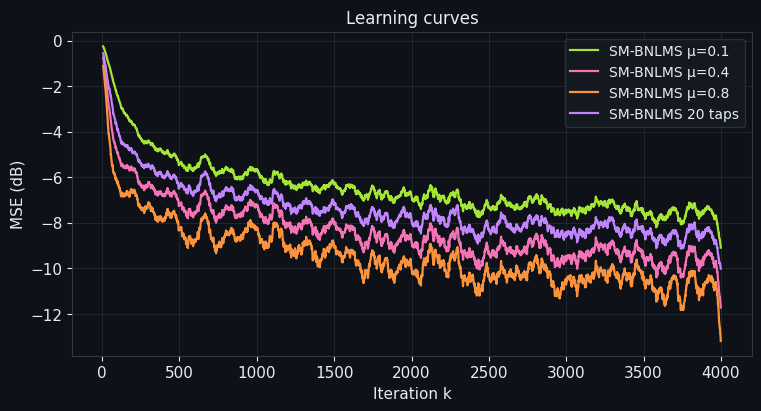

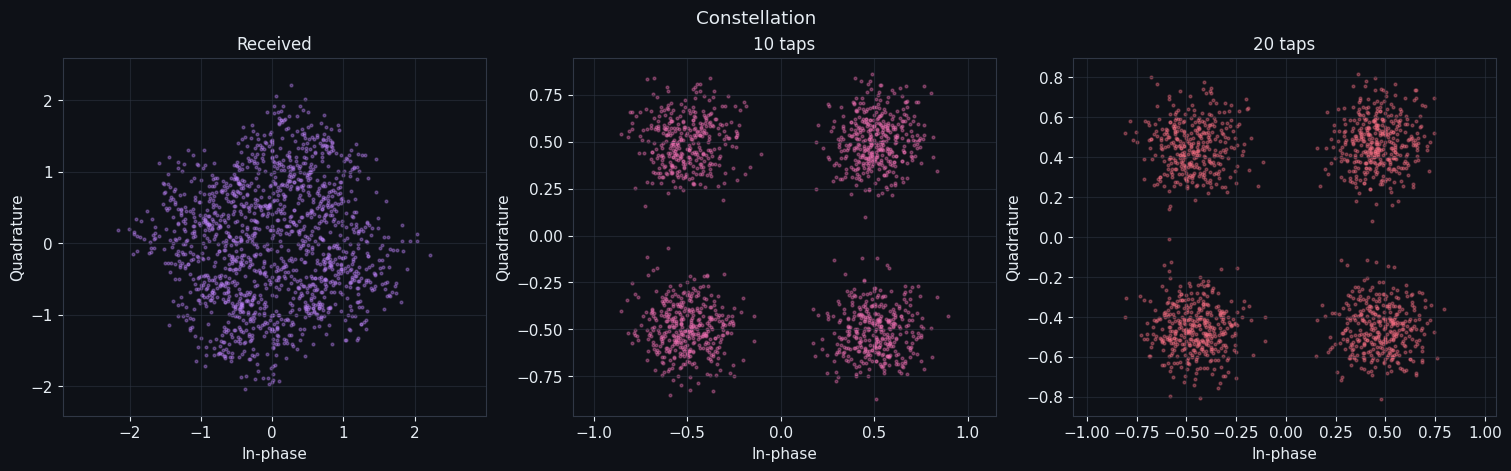

Model                                  Tail MSE     Tail MSD  Update rate
SM-BNLMS μ=0.1                          0.17767            —       20.42%
SM-BNLMS μ=0.4                          0.11124            —        7.15%
SM-BNLMS μ=0.8                         0.086332            —        4.38%
SM-BNLMS 20 taps                        0.14158            —       11.82%


In [4]:
plot.learning(results, window=64)
plot.show()
plot.constellation(
  {
    "Received": batch.x,
    "10 taps": results["SM-BNLMS μ=0.4"].y,
    "20 taps": results["SM-BNLMS 20 taps"].y
  }, start=2500)
plot.show()
training.summary(results)